# Quantitative tilt tolerancing of a vectorial off-axis parabolic mirror

This notebook builds the focus of the **off-axis segment** (same geometry and aperture
as the step-by-step notebook) and uses it to answer a quantitative question: **how much
mirror tilt can we tolerate before the focus stops being diffraction-limited?**

The incident field is placed on the mirror by an **exact closed-form ray/surface
intersection**, so no pupil-coordinate approximation is used. That matters for
tolerancing, where we need the wavefront (not just a pretty PSF).

**Pipeline.** For each incident ray:

$$
\text{ray} \xrightarrow{\text{intersect}} \mathbf r_m,(x_p,y_p)
\xrightarrow{\text{reflect}} \hat{\mathbf e}_r,\mathbf E_r
\xrightarrow{\text{apodise + Jacobian}} \text{angular spectrum}
\xrightarrow{\text{Debye sum}} \mathbf E(v,w).
$$

The focal field is the Debye–Wolf transform of the field on the reference sphere,
$$
\boxed{\;\mathbf E(v,w)=\iint P(k_v,k_w)\,e^{\,i(k_v v + k_w w)}\,dk_v\,dk_w\;}
$$
and everything below is about building $P$ correctly and reading the **wavefront
phase** out of it. All parameters are in the first code cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

# ================= parameters (edit these) =================
F    = 7.5e-3       # PARENT focal length [m]  (not the reflected focal length)
LAM  = 1030e-9      # wavelength [m]
APER = 12.7e-3      # clear aperture diameter [m]
K    = 2*np.pi/LAM  # wavenumber [1/m]
E_I  = np.array([0., 0., -1.])   # incident propagation direction (fixed lab beam)

# off-axis segment: 90-deg fold uses the parent section centred at rho0 = 2f
XC    = -2*F                     # off-axis centre on the parent (-> +x fold)
ZC    = XC**2/(4*F)              # chief-ray hit height on the parent
PIVOT = np.array([XC, 0., 0.])   # mount rotation point (as in the step-by-step notebook)

TILT_AXIS   = (1, 0, 0)          # lab axis the mirror is tilted about
EXAMPLE_DEG = 0.1                # tilt of the worked example in sections 2-5 [deg]
POL  = np.array([0., 1., 0.])    # input polarisation
W0   = 3.0e-3                    # Gaussian 1/e amplitude radius [m] (np.inf -> uniform)
ELL  = 1                         # vortex charge of the display input in section 7

RFL = F + XC**2/(4*F)            # reflected focal length (chief-ray hit point -> focus)
print(f"reflected focal length = {RFL*1e3:.2f} mm   RFL/D = {RFL/APER:.2f}   "
      f"nominal NA sin(atan(D/2RFL)) = {np.sin(np.arctan(APER/2/RFL)):.3f}")

reflected focal length = 15.00 mm   RFL/D = 1.18   nominal NA sin(atan(D/2RFL)) = 0.390


## 1. Geometry: surface, normal, rigid placement

**Parent paraboloid** with parent focal length $f$:
$$
z_p=\frac{x_p^2+y_p^2}{4f}.
$$
Writing the surface as a level set $F=z_p-\tfrac{x_p^2+y_p^2}{4f}=0$, the normal is
parallel to $\nabla F=(-x_p/2f,\,-y_p/2f,\,1)$, so
$$
\hat{\mathbf n}_p=\frac{(-x_p/2f,\,-y_p/2f,\,1)}{\sqrt{1+(x_p^2+y_p^2)/4f^2}} .
$$
The OAP is the part of the parent around $(X_C,0,Z_C)$. Tilt is a **rigid transform of
the mirror** about the mount point $\mathbf p_0$ (`PIVOT`), the input beam stays fixed:
$$
\mathbf r_{\text{lab}}=R\,(\mathbf r_p-\mathbf p_0)+\mathbf p_0\equiv R\,\mathbf r_p+\mathbf T,
\qquad \hat{\mathbf n}_{\text{lab}}=R\,\hat{\mathbf n}_p .
$$

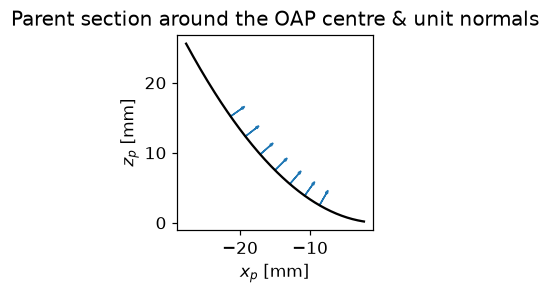

control  max| |n|-1 | = 2.220446049250313e-16


In [2]:
def rotation_matrix(axis, ang):
    a = np.asarray(axis, float); a = a/np.linalg.norm(a)
    Kx = np.array([[0,-a[2],a[1]],[a[2],0,-a[0]],[-a[1],a[0],0]])
    return np.eye(3) + np.sin(ang)*Kx + (1-np.cos(ang))*(Kx@Kx)

def z_parent(xp, yp):
    return (xp**2 + yp**2)/(4*F)

def normal_parent(xp, yp):
    n = np.stack([-xp/(2*F), -yp/(2*F), np.ones_like(np.asarray(xp, float))], axis=-1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

def placement(tilt_deg, axis=TILT_AXIS):
    """rigid placement of the mirror, rotated about PIVOT:  r_lab = R r_p + T"""
    R = rotation_matrix(axis, np.deg2rad(tilt_deg))
    return R, PIVOT - R @ PIVOT

# visual check: parent profile around the segment + a few unit normals
xx = np.linspace(XC-APER, XC+APER, 200)
plt.figure(figsize=(5,2.8))
plt.plot(xx*1e3, z_parent(xx,0)*1e3, 'k')
for x0 in np.linspace(XC-APER/2, XC+APER/2, 7):
    n = normal_parent(x0, 0.0); z0 = z_parent(x0, 0.0)
    plt.arrow(x0*1e3, z0*1e3, n[0]*2, n[2]*2, head_width=0.3, color='C0', lw=1)
plt.gca().set_aspect('equal'); plt.xlabel('$x_p$ [mm]'); plt.ylabel('$z_p$ [mm]')
plt.title('Parent section around the OAP centre & unit normals'); plt.tight_layout(); plt.show()

xr, yr = np.random.randn(2, 2000)*3e-3
print("control  max| |n|-1 | =", np.abs(np.linalg.norm(normal_parent(xr,yr),axis=-1)-1).max())

## 2. Exact ray/surface intersection (no pupil approximation)

A collimated ray enters at transverse $(X_{\text{in}},Y_{\text{in}})$ and travels
along $\hat{\mathbf e}_i=-\hat{\mathbf z}$. We must find **where it hits the tilted
surface** and sample the input field at the ray's own transverse coordinate.

Transform the ray $\mathbf r(s)=\mathbf r_{\text{in}}+s\,\hat{\mathbf e}_i$ into the
parent frame, $\mathbf r_p(s)=\mathbf a+s\,\mathbf d$ with
$\mathbf a=R^{\top}(\mathbf r_{\text{in}}-\mathbf T)$, $\mathbf d=R^{\top}\hat{\mathbf e}_i$.
Imposing $z_p=(x_p^2+y_p^2)/4f$ gives a **quadratic** $A s^2+Bs+C=0$:
$$
A=\frac{d_x^2+d_y^2}{4f},\quad
B=\frac{2(a_xd_x+a_yd_y)}{4f}-d_z,\quad
C=\frac{a_x^2+a_y^2}{4f}-a_z .
$$
For small tilts $A\to0$, and the textbook root $(-B+\sqrt{B^2-4AC})/2A$ subtracts two
nearly equal numbers. We use the cancellation-free pair $s_1=C/q$, $s_2=q/A$ with
$q=-\tfrac12\big(B+\operatorname{sgn}(B)\sqrt{B^2-4AC}\big)$ and take the first hit; the
control below checks it down to tiny tilts.

The clear aperture is the same as in the other notebooks: a circle of diameter `APER`
in the mirror-local $y_p$–$z_p$ plane, centred on the chief-ray hit point (body-fixed).
The plot shows how far the parent coordinate $(x_p,y_p)$ of each hit is from the ray's
own transverse coordinate $(X_{\text{in}},Y_{\text{in}})$ — the error a pupil-coordinate
approximation would make.

control  on-surface residual   : 1.973247953923618e-17
control  r_m == R r_p + T (err): 6.938893903907228e-18
control  on-surface residual at 0.0001 deg: 2.2e-17 m
control  on-surface residual at 1e-06 deg: 1.7e-17 m


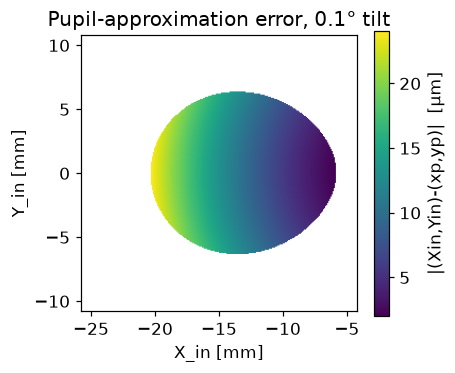

max mis-sampling = 24.1 µm  (avoided by the exact intersection)


In [3]:
def intersect(Xin, Yin, zin, R, t):
    """closed-form first intersection of the E_I rays with the transformed paraboloid"""
    Rt = R.T; d = Rt @ E_I
    rin = np.stack([Xin, Yin, np.full_like(Xin, zin)], -1)
    a = (rin - t) @ Rt.T
    ax, ay, az = a[...,0], a[...,1], a[...,2]; dx, dy, dz = d
    A = (dx**2+dy**2)/(4*F); B = 2*(ax*dx+ay*dy)/(4*F) - dz; C = (ax**2+ay**2)/(4*F) - az
    # cancellation-free roots: s1 = C/q, s2 = q/A. The naive (-B+disc)/(2A) loses all
    # precision when A -> 0 (tiny tilts); this form degrades smoothly to s = -C/B.
    disc = np.sqrt(np.maximum(B**2-4*A*C, 0.0))
    q = -0.5*(B + np.where(B >= 0, disc, -disc))
    s1 = C/q
    s2 = q/A if A != 0 else np.full_like(s1, np.inf)
    s = np.where((s1>0) & ((s1<s2)|(s2<=0)), s1, s2)          # first hit
    r_p = a + s[...,None]*d
    r_m = rin + s[...,None]*E_I              # equals R r_p + t
    return r_p[...,0], r_p[...,1], r_p, r_m

def aperture_mask(xp, yp, D=APER, y0=0.0, z0=ZC):
    """Clear aperture (same definition in all notebooks): a circle of diameter D in
    the mirror-local y_p-z_p plane, i.e. seen along the local fold axis, centred on
    the chief-ray hit point (y0, z0). Takes parent coordinates, so it is body-fixed
    and moves rigidly with the mirror under any tilt/shift."""
    zp = (xp**2 + yp**2)/(4*F)
    return ((yp-y0)**2 + (zp-z0)**2 <= (D/2)**2) & (xp*XC > 0)   # the XC side of the parent

# ---- input ray grid, centred on the off-axis footprint
pix = 260; Lpup = 1.7*APER; zin = 0.05
xi = (np.arange(pix) - pix/2)*(Lpup/pix)
Xin = XC + np.meshgrid(xi, xi, indexing='xy')[0]
Yin =      np.meshgrid(xi, xi, indexing='xy')[1]
dA = (Lpup/pix)**2
ext = [(XC-Lpup/2)*1e3, (XC+Lpup/2)*1e3, -Lpup/2*1e3, Lpup/2*1e3]

# ---- worked example threaded through sections 2-5
R, T = placement(EXAMPLE_DEG)
xp, yp, r_p, r_m = intersect(Xin, Yin, zin, R, T)
inside = aperture_mask(xp, yp)

print("control  on-surface residual   :", np.abs(z_parent(xp,yp)-r_p[...,2])[inside].max())
print("control  r_m == R r_p + T (err):", np.abs(r_m - (r_p@R.T + T))[inside].max())
for tiny in (1e-4, 1e-6):
    Rq, Tq = placement(tiny)
    xq, yq, rq, _ = intersect(Xin, Yin, zin, Rq, Tq)
    print(f"control  on-surface residual at {tiny:g} deg: "
          f"{np.abs(z_parent(xq,yq)-rq[...,2])[aperture_mask(xq,yq)].max():.1e} m")

miss = np.hypot(Xin - xp, Yin - yp)
plt.figure(figsize=(4.5,3.6))
im = plt.imshow(np.where(inside, miss*1e6, np.nan), origin='lower', extent=ext, cmap='viridis')
plt.colorbar(im, label='|(Xin,Yin)-(xp,yp)|  [µm]')
plt.xlabel('X_in [mm]'); plt.ylabel('Y_in [mm]')
plt.title(f'Pupil-approximation error, {EXAMPLE_DEG}° tilt')
plt.tight_layout(); plt.show()
print(f"max mis-sampling = {miss[inside].max()*1e6:.1f} µm  (avoided by the exact intersection)")

## 3. Reflection

**Direction** (Householder reflection, preserves length):
$$
\hat{\mathbf e}_r=\hat{\mathbf e}_i-2(\hat{\mathbf e}_i\!\cdot\!\hat{\mathbf n})\hat{\mathbf n}.
$$
**Field** (ideal conductor; isolate this to swap in Fresnel $s/p$ later):
$$
\mathbf E_r=-\mathbf E_i+2(\mathbf E_i\!\cdot\!\hat{\mathbf n})\hat{\mathbf n},
\qquad \hat{\mathbf e}_r\!\cdot\!\mathbf E_r=-(\hat{\mathbf e}_i\!\cdot\!\mathbf E_i),
$$
so a transverse input stays transverse after reflection.

In [4]:
def reflect_dir(e_i, n):
    return e_i - 2*np.sum(e_i*n, axis=-1, keepdims=True)*n

def reflect_field(E, n):
    return -E + 2*np.sum(E*n, axis=-1, keepdims=True)*n

n_lab = normal_parent(xp, yp) @ R.T
e_r = reflect_dir(E_I, n_lab)

print("control  max| |e_r|-1 |        :", np.abs(np.linalg.norm(e_r,axis=-1)-1)[inside].max())
E_unit = np.broadcast_to(POL, e_r.shape)
print("control  max|E_r . e_r| (transv):", np.abs(np.sum(reflect_field(E_unit,n_lab)*e_r,axis=-1))[inside].max())

control  max| |e_r|-1 |        : 7.771561172376096e-16
control  max|E_r . e_r| (transv): 3.885780586188048e-16


## 4. Focusing map, apodisation, and the flux Jacobian

Let $\theta$ be the ray angle from the output axis, $\cos\theta=\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf u}$.
Two **separate** weights turn the reflected field into the angular spectrum:

* **Physical apodisation** (energy conservation on the parabola):
  $q(\theta)=\sec^2(\theta/2)=2/(1+\cos\theta)$.
* **Solid-angle ↔ k-space Jacobian:** $d\Omega=\dfrac{dk_v\,dk_w}{k\,k_u}$.

Because we integrate over the *incident-beam area* $dA_{\text{in}}$, the two combine into
a single **energy-conserving amplitude weight** per ray,
$$
\text{weight}=\sqrt{\;\underbrace{\frac{d\Omega}{dA_{\text{in}}}}_{J}\;},
\qquad
J=\frac{\bigl|\det\partial(k_v,k_w)/\partial(X_{\text{in}},Y_{\text{in}})\bigr|}{k\,k_u},
$$
which we obtain by finite-differencing the (smooth) map $(X_{\text{in}},Y_{\text{in}})\!\to\!(k_v,k_w)$.
The control below checks $J$ against the closed form $\cos^4(\theta/2)/f^2$ on the
aligned mirror.

control  J_numeric / J_analytic (aligned): mean=0.99998  scatter=1.4e-05


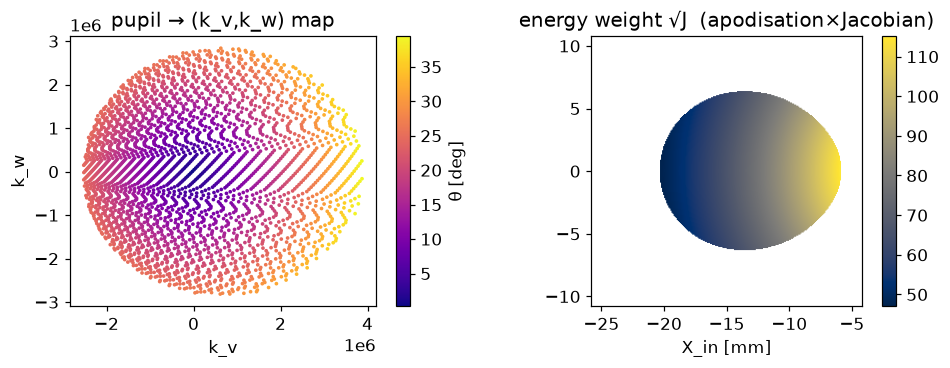

In [5]:
def output_basis(e_r_inside):
    u = e_r_inside.mean(0); u /= np.linalg.norm(u)          # track the mean ray
    ref = np.array([0,0,1.]) if abs(u[2]) < 0.9 else np.array([1,0,0.])
    v = ref - np.dot(ref,u)*u; v /= np.linalg.norm(v)
    w = np.cross(u, v)
    return u, v, w

def flux_jacobian(kv, kw, ku, xi):
    dkv_dy, dkv_dx = np.gradient(kv, xi, xi)
    dkw_dy, dkw_dx = np.gradient(kw, xi, xi)
    det = np.abs(dkv_dx*dkw_dy - dkv_dy*dkw_dx)
    return det/(K*np.maximum(ku, 1e-9))

u,v,w = output_basis(e_r[inside])
kv = K*(e_r@v); kw = K*(e_r@w); ku = K*(e_r@u)
Jflux = flux_jacobian(kv, kw, ku, xi)
weight = np.sqrt(np.maximum(Jflux, 0.0))

# ---- control: aligned mirror, J against cos^4(theta_p/2)/f^2 (theta_p from the parent axis)
xp0,yp0,_,_ = intersect(Xin, Yin, zin, np.eye(3), np.zeros(3))
ins0 = aperture_mask(xp0, yp0)
e_r0 = reflect_dir(E_I, normal_parent(xp0,yp0))
ub,vb,wb = output_basis(e_r0[ins0])
J0 = flux_jacobian(K*(e_r0@vb), K*(e_r0@wb), K*(e_r0@ub), xi)
cos_tp = e_r0[...,2]
J_analytic = ((1+cos_tp)/2)**2 / F**2
ratio = (J0/J_analytic)[ins0]
print(f"control  J_numeric / J_analytic (aligned): mean={ratio.mean():.5f}  "
      f"scatter={ratio.std()/ratio.mean():.1e}")

fig,ax = plt.subplots(1,2, figsize=(9,3.4))
sc = ax[0].scatter((kv[inside])[::7], (kw[inside])[::7], s=2,
                   c=np.degrees(np.arccos(np.clip(ku[inside]/K,-1,1)))[::7], cmap='plasma')
ax[0].set_title('pupil → (k_v,k_w) map'); ax[0].set_xlabel('k_v'); ax[0].set_ylabel('k_w')
ax[0].set_aspect('equal'); plt.colorbar(sc, ax=ax[0], label='θ [deg]')
im = ax[1].imshow(np.where(inside, weight, np.nan), origin='lower', extent=ext, cmap='cividis')
ax[1].set_title('energy weight √J  (apodisation×Jacobian)')
ax[1].set_xlabel('X_in [mm]'); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## 5. The wavefront (optical path) — the quantity tolerancing lives on

Along each reflected ray the optical path to the focal reference is
$$
L=\underbrace{(\mathbf r_m-\mathbf p_{\text{ref}})\!\cdot\!\hat{\mathbf e}_i}_{L_{\text{in}}}
+\underbrace{\hat{\mathbf e}_r\!\cdot\!(\mathbf F-\mathbf r_m)}_{\text{to plane through }\mathbf F},
\qquad \varphi_{\text{OPD}}=k\,(L-\langle L\rangle).
$$
For the aligned mirror $L$ is constant (perfect focus).

**Where is $\mathbf F$?** A tilted mirror with a fixed input beam has *no* stigmatic
focus, and the rigidly-transformed parent focus is **wrong** (it injects many waves of
spurious tilt). We use the least-squares crossing of the reflected rays, which minimises
$\sum_i\lVert(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})(\mathbf F-\mathbf r_{m,i})\rVert^2$:
$$
\Big[\textstyle\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\Big]\mathbf F
=\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\mathbf r_{m,i}.
$$

**Spot motion is not aberration.** $\mathbf F$ is a geometric estimate, so
$\varphi_{\text{OPD}}$ still contains piston and terms linear in $(k_v,k_w,k_u)$. Moving the
observation point by $(\delta v,\delta w,\delta u)$ adds exactly
$k_v\delta v+k_w\delta w+k_u\delta u$ to every ray, so these terms only move the spot.
`wavefront_stats` removes them by a least-squares fit weighted by $a^2$,
$a=|E_\text{in}|\sqrt J$, and reports from the residual $\varphi_\text{res}$
$$
\sigma=\sqrt{\langle\varphi_\text{res}^2\rangle_{a^2}}\,/\,2\pi,\qquad
S=\frac{\big|\sum a\,e^{i\varphi_\text{res}}\big|^2}{\big(\sum a\big)^2},
$$
the RMS wavefront (waves) and the Strehl ratio = peak intensity at the best point over
the unaberrated peak (scalar). The same function is used in all notebooks. For
non-uniform illumination $S\approx e^{-(2\pi\sigma)^2}$ holds only roughly, because $S$
weights by amplitude and $\sigma$ by intensity.

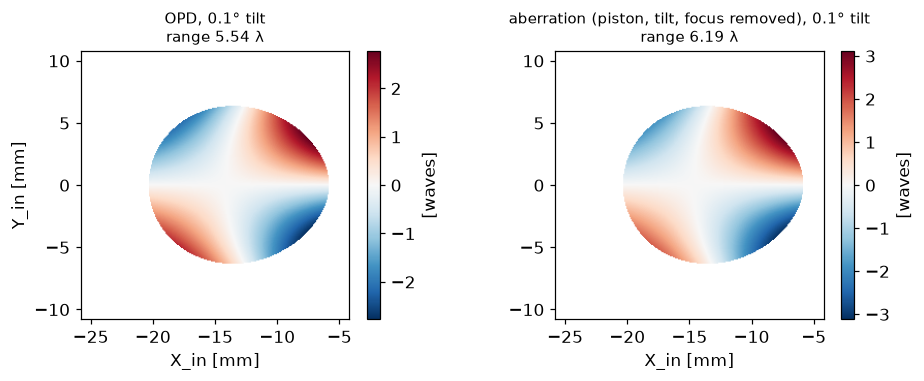

RMS = 0.246 λ   Strehl = 0.093   PtV = 6.19 λ   (Gaussian w0 = 3 mm)
best point relative to F (dv, dw, du) = [-0.009  0.85  -0.146] µm


In [6]:
def ls_focus(e_r_in, r_m_in):
    P = np.eye(3) - e_r_in[:,:,None]*e_r_in[:,None,:]
    return np.linalg.solve(P.sum(0), np.einsum('nij,nj->i', P, r_m_in))

def opd_phase(e_r, r_m, Fpt, inside, zin):
    L_in  = np.sum((r_m - np.array([0.,0.,zin]))*E_I, axis=-1)
    L_out = np.sum(e_r*(Fpt - r_m), axis=-1)
    L = L_in + L_out
    return K*(L - L[inside].mean())

def wavefront_stats(phi, amp, kv, kw, ku):
    """Wavefront statistics (same definition in all notebooks).

    phi : OPD phase of each ray [rad];  amp : real ray amplitude |E_in|*sqrt(J)
    kv, kw, ku : ray wavevector on the output basis.

    Moving the observation point by (dv, dw, du) multiplies each plane wave by
    exp(i(kv dv + kw dw + ku du)), so piston and the parts of phi linear in
    (kv, kw, ku) only move the spot (pointing and focus shift), they do not blur it.
    They are removed by a least-squares fit weighted by amp**2; what is left is the
    aberration.

    rms    : amp**2-weighted RMS of the residual [waves]
    strehl : |sum amp e^{i res}|^2 / (sum amp)^2, the peak intensity at the best
             (shifted) point over the unaberrated peak (scalar, polarisation ignored)
    ptv    : peak-to-valley of the residual [waves]
    shift  : (dv, dw, du) of that best point from the reference focus [m]
    """
    k0 = np.sqrt(kv**2 + kw**2 + ku**2).mean()
    M = np.stack([np.ones_like(kv), kv/k0, kw/k0, (ku - ku.mean())/k0], -1)
    sw = amp/np.sqrt(np.sum(amp**2))
    c = np.linalg.lstsq(M*sw[:, None], phi*sw, rcond=None)[0]
    res = phi - M @ c
    rms = np.sqrt(np.sum(amp**2*res**2)/np.sum(amp**2))/(2*np.pi)
    strehl = np.abs(np.sum(amp*np.exp(1j*res)))**2/np.sum(amp)**2
    ptv = (res.max() - res.min())/(2*np.pi)
    return dict(rms=rms, strehl=strehl, ptv=ptv, shift=-c[1:]/k0, residual=res)

def gauss(X, Y, w0=W0, l=0):
    """input field centred on the off-axis footprint (XC, 0)"""
    x, y = X - XC, Y
    g = np.exp(-(x**2 + y**2)/w0**2).astype(complex)
    return g*np.exp(1j*l*np.arctan2(y, x)) if l else g

Fpt = ls_focus(e_r[inside], r_m[inside])
phi = opd_phase(e_r, r_m, Fpt, inside, zin)
st = wavefront_stats(phi[inside], (np.abs(gauss(Xin, Yin))*weight)[inside],
                     kv[inside], kw[inside], ku[inside])

Wraw = np.where(inside, phi/(2*np.pi), np.nan)
Wres = np.full(phi.shape, np.nan); Wres[inside] = st['residual']/(2*np.pi)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a_, Wm, ttl in [(ax[0], Wraw, 'OPD'), (ax[1], Wres, 'aberration (piston, tilt, focus removed)')]:
    lim = np.nanmax(np.abs(Wm))
    im = a_.imshow(Wm, origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(im, ax=a_, fraction=.046, label='[waves]')
    a_.set_title(f'{ttl}, {EXAMPLE_DEG}° tilt\nrange {np.nanmax(Wm)-np.nanmin(Wm):.2f} λ', fontsize=10)
    a_.set_xlabel('X_in [mm]')
ax[0].set_ylabel('Y_in [mm]'); plt.tight_layout(); plt.show()
print(f"RMS = {st['rms']:.3f} λ   Strehl = {st['strehl']:.3f}   PtV = {st['ptv']:.2f} λ   "
      f"(Gaussian w0 = {W0*1e3:g} mm)")
print("best point relative to F (dv, dw, du) =", np.round(st['shift']*1e6, 3), "µm")

## 6. The Debye sum

Each component transforms independently (the kernel is scalar):
$$
E_{x,y,z}(v,w)=\sum_{\text{rays}} \big[\mathbf E_r\big]_{x,y,z}\,\sqrt{J}\;e^{i\varphi_{\text{OPD}}}\;
e^{\,i(k_v v+k_w w)}\,dA_{\text{in}},
\qquad I=|E_x|^2+|E_y|^2+|E_z|^2 .
$$
Evaluated as a **non-uniform DFT** (two dense matmuls) — exact, no scattered
interpolation. We wrap the whole chain into one function and validate that the aligned
mirror gives a centred, Strehl-1 focus.

In [7]:
def debye(col, kvf, kwf, vax, wax):
    Mv = np.exp(1j*np.outer(vax, kvf)); Mw = np.exp(1j*np.outer(wax, kwf))
    return ((Mv*col[None,:]) @ Mw.T).T

def exact_oap(field_fn, tilt_deg, axis=TILT_AXIS, pol=POL, pix=260, pupil_pad=1.7,
              zin=0.05, Lout=40e-6, Nout=160):
    R, T = placement(tilt_deg, axis)
    Lp = pupil_pad*APER
    xi = (np.arange(pix)-pix/2)*(Lp/pix); dA = (Lp/pix)**2
    Xin = XC + np.meshgrid(xi, xi, indexing='xy')[0]
    Yin =      np.meshgrid(xi, xi, indexing='xy')[1]
    xp, yp, r_p, r_m = intersect(Xin, Yin, zin, R, T)
    inside = aperture_mask(xp, yp)

    n_lab = normal_parent(xp, yp) @ R.T
    e_r = reflect_dir(E_I, n_lab)
    Ein = field_fn(Xin, Yin)                      # sampled at the ray's OWN coordinate
    p = np.asarray(pol, float); p /= np.linalg.norm(p)
    E_r = reflect_field(Ein[...,None]*p, n_lab)

    u,v,w = output_basis(e_r[inside])
    kv = K*(e_r@v); kw = K*(e_r@w); ku = K*(e_r@u)
    weight = np.sqrt(np.maximum(flux_jacobian(kv,kw,ku,xi), 0.0))
    Fpt = ls_focus(e_r[inside], r_m[inside])
    phi = opd_phase(e_r, r_m, Fpt, inside, zin)

    m = inside
    a = (E_r[m]*(weight[m]*np.exp(1j*phi[m]))[:,None])*dA
    vax = (np.arange(Nout)-Nout/2)*(Lout/Nout)
    Ex = debye(a[:,0], kv[m], kw[m], vax, vax)
    Ey = debye(a[:,1], kv[m], kw[m], vax, vax)
    Ez = debye(a[:,2], kv[m], kw[m], vax, vax)

    st = wavefront_stats(phi[m], np.abs(Ein[m])*weight[m], kv[m], kw[m], ku[m])
    return dict(Ex=Ex, Ey=Ey, Ez=Ez, vax=vax, rms=st['rms'], strehl=st['strehl'],
                ptv=st['ptv'], shift=st['shift'])

o0 = exact_oap(gauss, 0.0)
I0 = np.abs(o0['Ex'])**2+np.abs(o0['Ey'])**2+np.abs(o0['Ez'])**2
iy,ix = np.unravel_index(np.argmax(I0), I0.shape)
print(f"aligned validation: peak@({ix-80},{iy-80})px  Strehl={o0['strehl']:.4f}  PtV={o0['ptv']:.1e} waves")

aligned validation: peak@(0,0)px  Strehl=1.0000  PtV=2.9e-11 waves


## 7. Final field for a few tilts

Total intensity $|E|^2$ for several tilts, with the display input `gauss(..., l=ELL)`
(a vortex makes aberrations easy to see). Panels are re-centred on the intensity peak
(the mm-scale walk-off of the beam is pure pointing and removed for display).

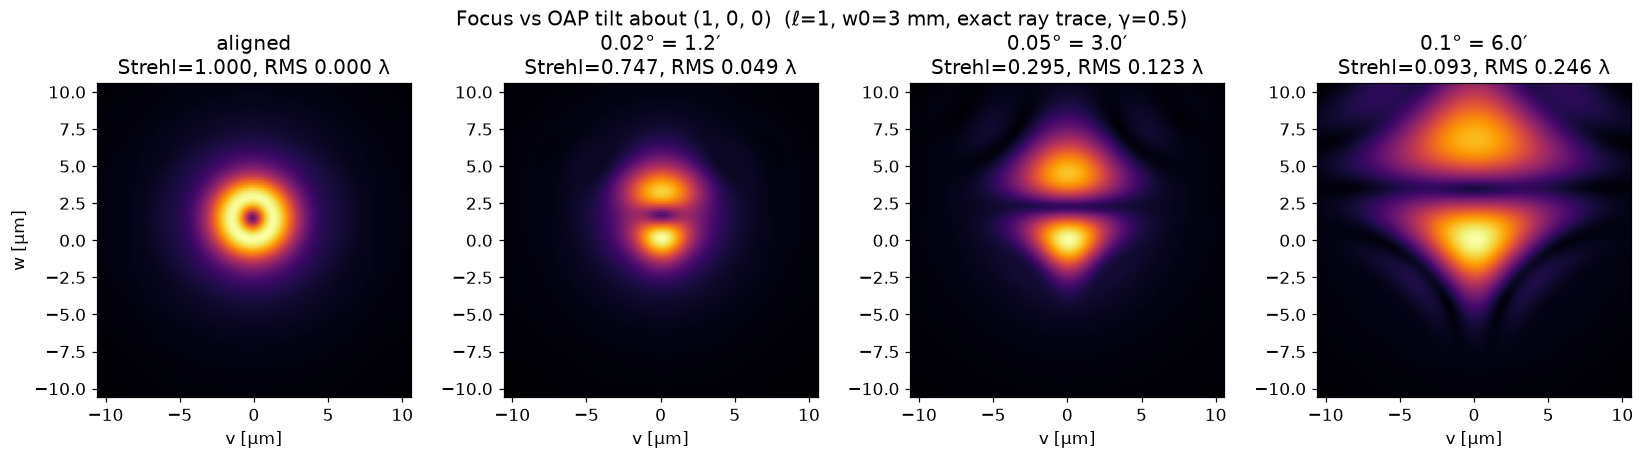

In [8]:
tilts = [0.0, 0.02, 0.05, 0.1]          # [deg]
fig, axes = plt.subplots(1, len(tilts), figsize=(3.75*len(tilts), 4.0), constrained_layout=True)
from matplotlib.colors import PowerNorm
for ax, deg in zip(axes, tilts):
    o = exact_oap(lambda X,Y: gauss(X,Y,l=ELL), deg, Lout=30e-6, Nout=170)
    I = np.abs(o['Ex'])**2+np.abs(o['Ey'])**2+np.abs(o['Ez'])**2
    # recentre display on the intensity peak
    iy,ix = np.unravel_index(np.argmax(I), I.shape)
    h = 60
    iy = min(max(iy,h), I.shape[0]-h); ix = min(max(ix,h), I.shape[1]-h)
    crop = I[iy-h:iy+h, ix-h:ix+h]; crop /= crop.max()
    dv = (o['vax'][1]-o['vax'][0])*1e6
    e2 = [-h*dv, h*dv, -h*dv, h*dv]
    im = ax.imshow(crop, origin='lower', extent=e2, cmap='inferno', norm=PowerNorm(0.5))
    lab = 'aligned' if deg==0 else f'{deg}° = {deg*60:.1f}′'
    ax.set_title(f"{lab}\nStrehl={o['strehl']:.3f}, RMS {o['rms']:.3f} λ")
    ax.set_xlabel('v [µm]')
axes[0].set_ylabel('w [µm]')
fig.suptitle(f'Focus vs OAP tilt about {TILT_AXIS}  (ℓ={ELL}, w0={W0*1e3:g} mm, exact ray trace, γ=0.5)',
             fontsize=13)
plt.show()

## 8. Quantitative tolerancing

We scan the tilt and, for each, compute the RMS wavefront $\sigma$ and the Strehl ratio
$S$ of section 5 (spot motion removed). The tolerance is the tilt where $S$ drops to
0.8 (and 0.9), read off the scan by interpolation. It depends on the input beam (`W0`),
the tilt axis and the aperture, so rerun after changing them. If $S$ stays above the
level over the whole scan, extend `degs`.

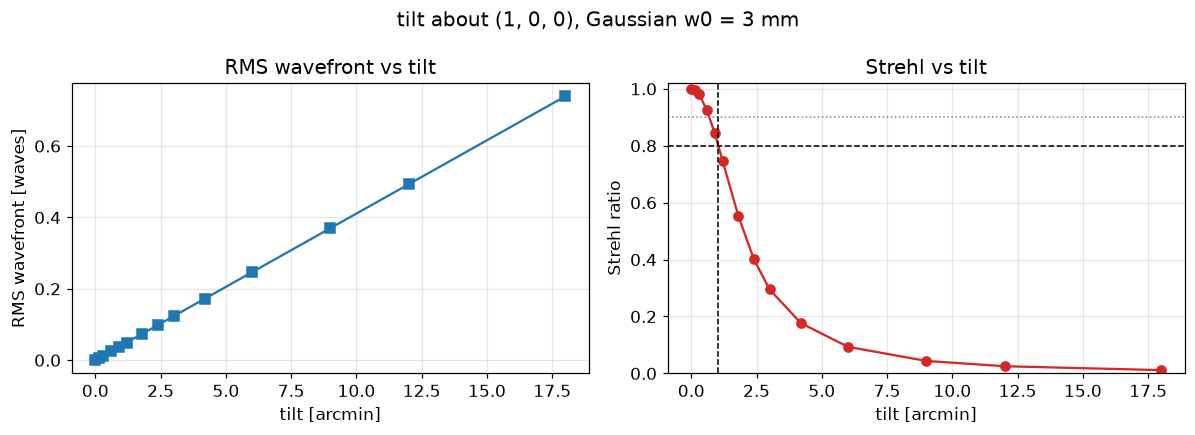

S >= 0.8: tilt <= 1.03 arcmin  (17.2 mdeg)
S >= 0.9: tilt <= 0.69 arcmin  (11.5 mdeg)


In [9]:
degs = np.array([0, .0025, .005, .01, .015, .02, .03, .04, .05, .07, .1, .15, .2, .3])   # [deg]
rms = []; strehl = []
for d in degs:
    o = exact_oap(gauss, d, Nout=4, Lout=1e-6)      # only the statistics are needed here
    rms.append(o['rms']); strehl.append(o['strehl'])
rms = np.array(rms); strehl = np.array(strehl)

def tilt_at(level):
    """first tilt where the scanned Strehl drops below `level` (linear interpolation)"""
    below = np.nonzero(strehl < level)[0]
    if len(below) == 0:
        return np.nan
    i = below[0]
    return np.interp(level, [strehl[i], strehl[i-1]], [degs[i], degs[i-1]])

tol80, tol90 = tilt_at(0.8), tilt_at(0.9)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
ax[0].plot(degs*60, rms, 's-')
ax[0].set_xlabel('tilt [arcmin]'); ax[0].set_ylabel('RMS wavefront [waves]')
ax[0].grid(alpha=.3); ax[0].set_title('RMS wavefront vs tilt')
ax[1].plot(degs*60, strehl, 'o-', color='C3')
ax[1].axhline(0.8, ls='--', c='k', lw=1); ax[1].axhline(0.9, ls=':', c='gray', lw=1)
if np.isfinite(tol80): ax[1].axvline(tol80*60, ls='--', c='k', lw=1)
ax[1].set_xlabel('tilt [arcmin]'); ax[1].set_ylabel('Strehl ratio')
ax[1].set_ylim(0,1.02); ax[1].grid(alpha=.3); ax[1].set_title('Strehl vs tilt')
fig.suptitle(f'tilt about {TILT_AXIS}, Gaussian w0 = {W0*1e3:g} mm'); plt.tight_layout(); plt.show()

for lev, tol in [(0.8, tol80), (0.9, tol90)]:
    if np.isfinite(tol):
        print(f"S >= {lev}: tilt <= {tol*60:.2f} arcmin  ({tol*1e3:.1f} mdeg)")
    else:
        print(f"S >= {lev}: not reached up to {degs[-1]*60:.1f} arcmin -- extend degs")

## Summary

* The focus of the off-axis segment is built from the exact 3-D geometry with a
  **closed-form ray/surface intersection** (cancellation-free, so it stays exact for
  tiny tilts); there is no pupil-coordinate approximation.
* Tolerances come from the Strehl ratio with **spot motion removed** (piston, tilt and
  focus shift), read off the scan in section 8 for the chosen input beam and tilt axis.

**Caveats.** (1) Ideal-conductor reflection (no Fresnel $s/p$ phase; see the
perfect-vs-gold notebook). (2) The Strehl is at the best point, i.e. the beam is allowed
to re-point and refocus; a fixed detector or fibre sees the spot move as well (the
shift is returned by `wavefront_stats`). (3) Scalar Strehl; the polarisation structure
of the focus is not included. (4) The input is collimated along $-\hat{\mathbf z}$.
(5) The $O(N_{\text{pupil}}N_{\text{out}})$ sum is exact but not fast — swap in a NUFFT
for large sweeps.